# Binary prediction of smoker status from health measurements

Machine Learning final project, MS Business Analytics, Rensselaer Polytechnic Institute (spring 2024).

**Data.** Kaggle Playground Series S3E24, *Binary Prediction of Smoker Status using Bio-Signals*: a public,
synthetic dataset of 159,255 records with 22 health measurements (age, body measurements, blood pressure,
blood and urine tests, dental caries) and smoking status. The data are not included; download `train.csv`
from the competition page.

**Goal.** Predict smoking status (scored by ROC AUC), and look at which measurements carry the most
information about smoking.

**Sections.** 1 Data exploration · 2 Class imbalance and a baseline random forest · 3 Hyperparameter tuning ·
4 Other models · 5 Feature importance · 6 Visualizing the results · 7 Model comparison · 8 Height as a
categorical variable

## 1. Data exploration
Descriptive statistics, distributions of age, height and weight, class balance and correlations; the numerical features are then standardized.

In [ ]:
#load the training data
import pandas as pd
train = pd.read_csv('train.csv')
train.head()

,id,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,...,HDL,LDL,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,dental caries,smoking
0,0,55,165,60,81.0,0.5,0.6,1,1,135,...,40,75,16.5,1,1.0,22,25,27,0,1
1,1,70,165,65,89.0,0.6,0.7,2,2,146,...,57,126,16.2,1,1.1,27,23,37,1,0
2,2,20,170,75,81.0,0.4,0.5,1,1,118,...,45,93,17.4,1,0.8,27,31,53,0,1
3,3,35,180,95,105.0,1.5,1.2,1,1,131,...,38,102,15.9,1,1.0,20,27,30,1,0
4,4,30,165,60,80.5,1.5,1.0,1,1,121,...,44,93,15.4,1,0.8,19,13,17,0,1


In [ ]:
# Calculate descriptive statistics for numerical columns
descriptive_stats = train.describe()

# Round the stats to two decimal places
descriptive_stats_rounded = descriptive_stats.round(2)

# Save the rounded descriptive statistics to a CSV file
descriptive_stats_rounded.to_csv('descriptive_stats.csv')

from google.colab import files
files.download('descriptive_stats.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

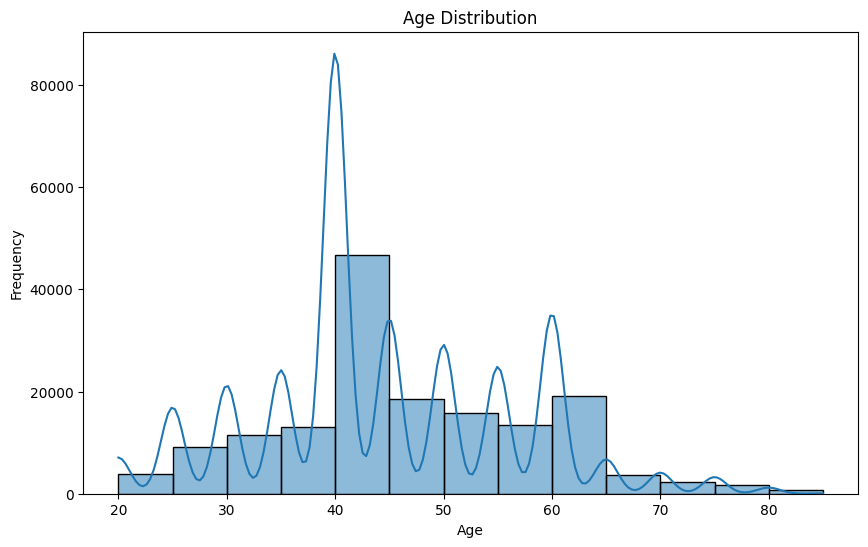

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


#histogram for Age distribution
plt.figure(figsize=(10, 6))
sns.histplot(train['age'], kde=True, binwidth=5)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()


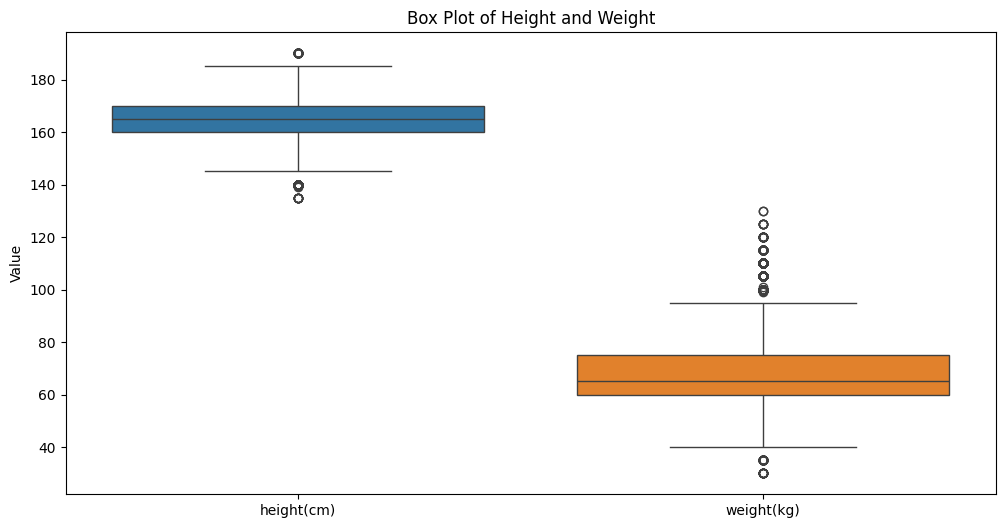

In [ ]:
#Boxplot for height and weight
plt.figure(figsize=(12, 6))
sns.boxplot(data=train[['height(cm)', 'weight(kg)']])
plt.title('Box Plot of Height and Weight')
plt.ylabel('Value')
plt.show()


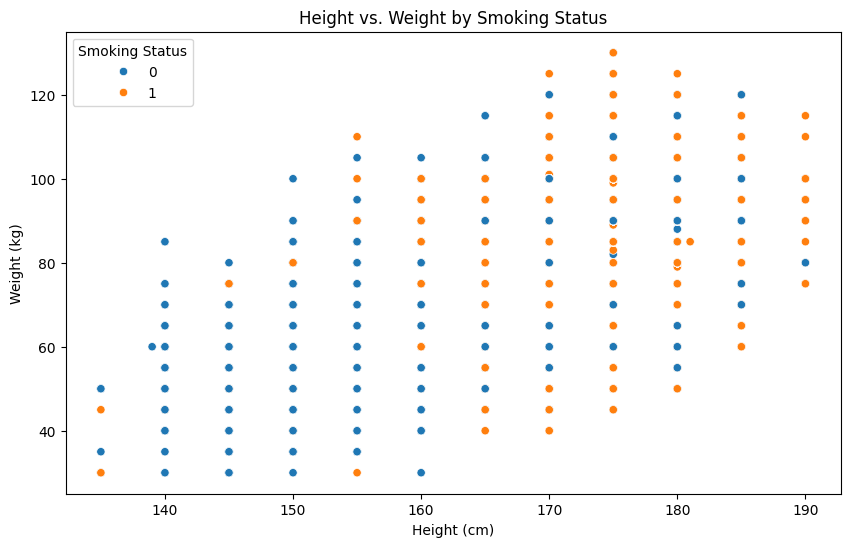

In [ ]:
# Scatter Plot for Height vs. Weight
plt.figure(figsize=(10, 6))
sns.scatterplot(x='height(cm)', y='weight(kg)', data=train, hue='smoking')
plt.title('Height vs. Weight by Smoking Status')
plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')
plt.legend(title='Smoking Status')
plt.show()


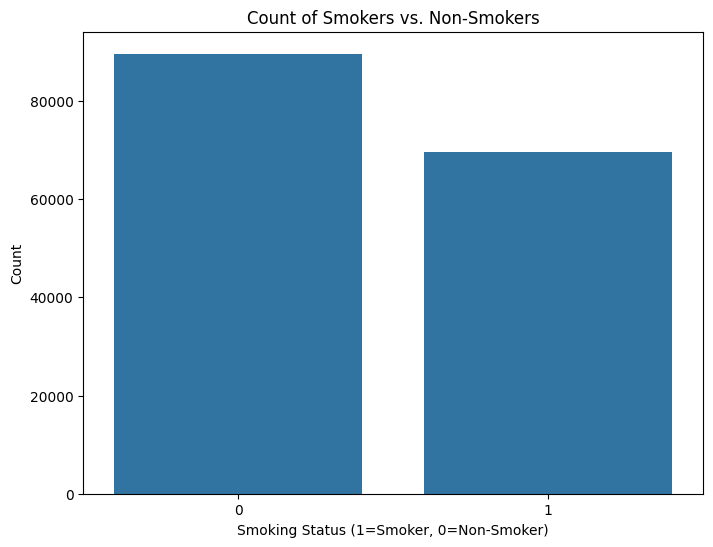

In [ ]:
#Bar Chart for Smoking Status
plt.figure(figsize=(8, 6))
sns.countplot(x='smoking', data=train)
plt.title('Count of Smokers vs. Non-Smokers')
plt.xlabel('Smoking Status (1=Smoker, 0=Non-Smoker)')
plt.ylabel('Count')
plt.show()


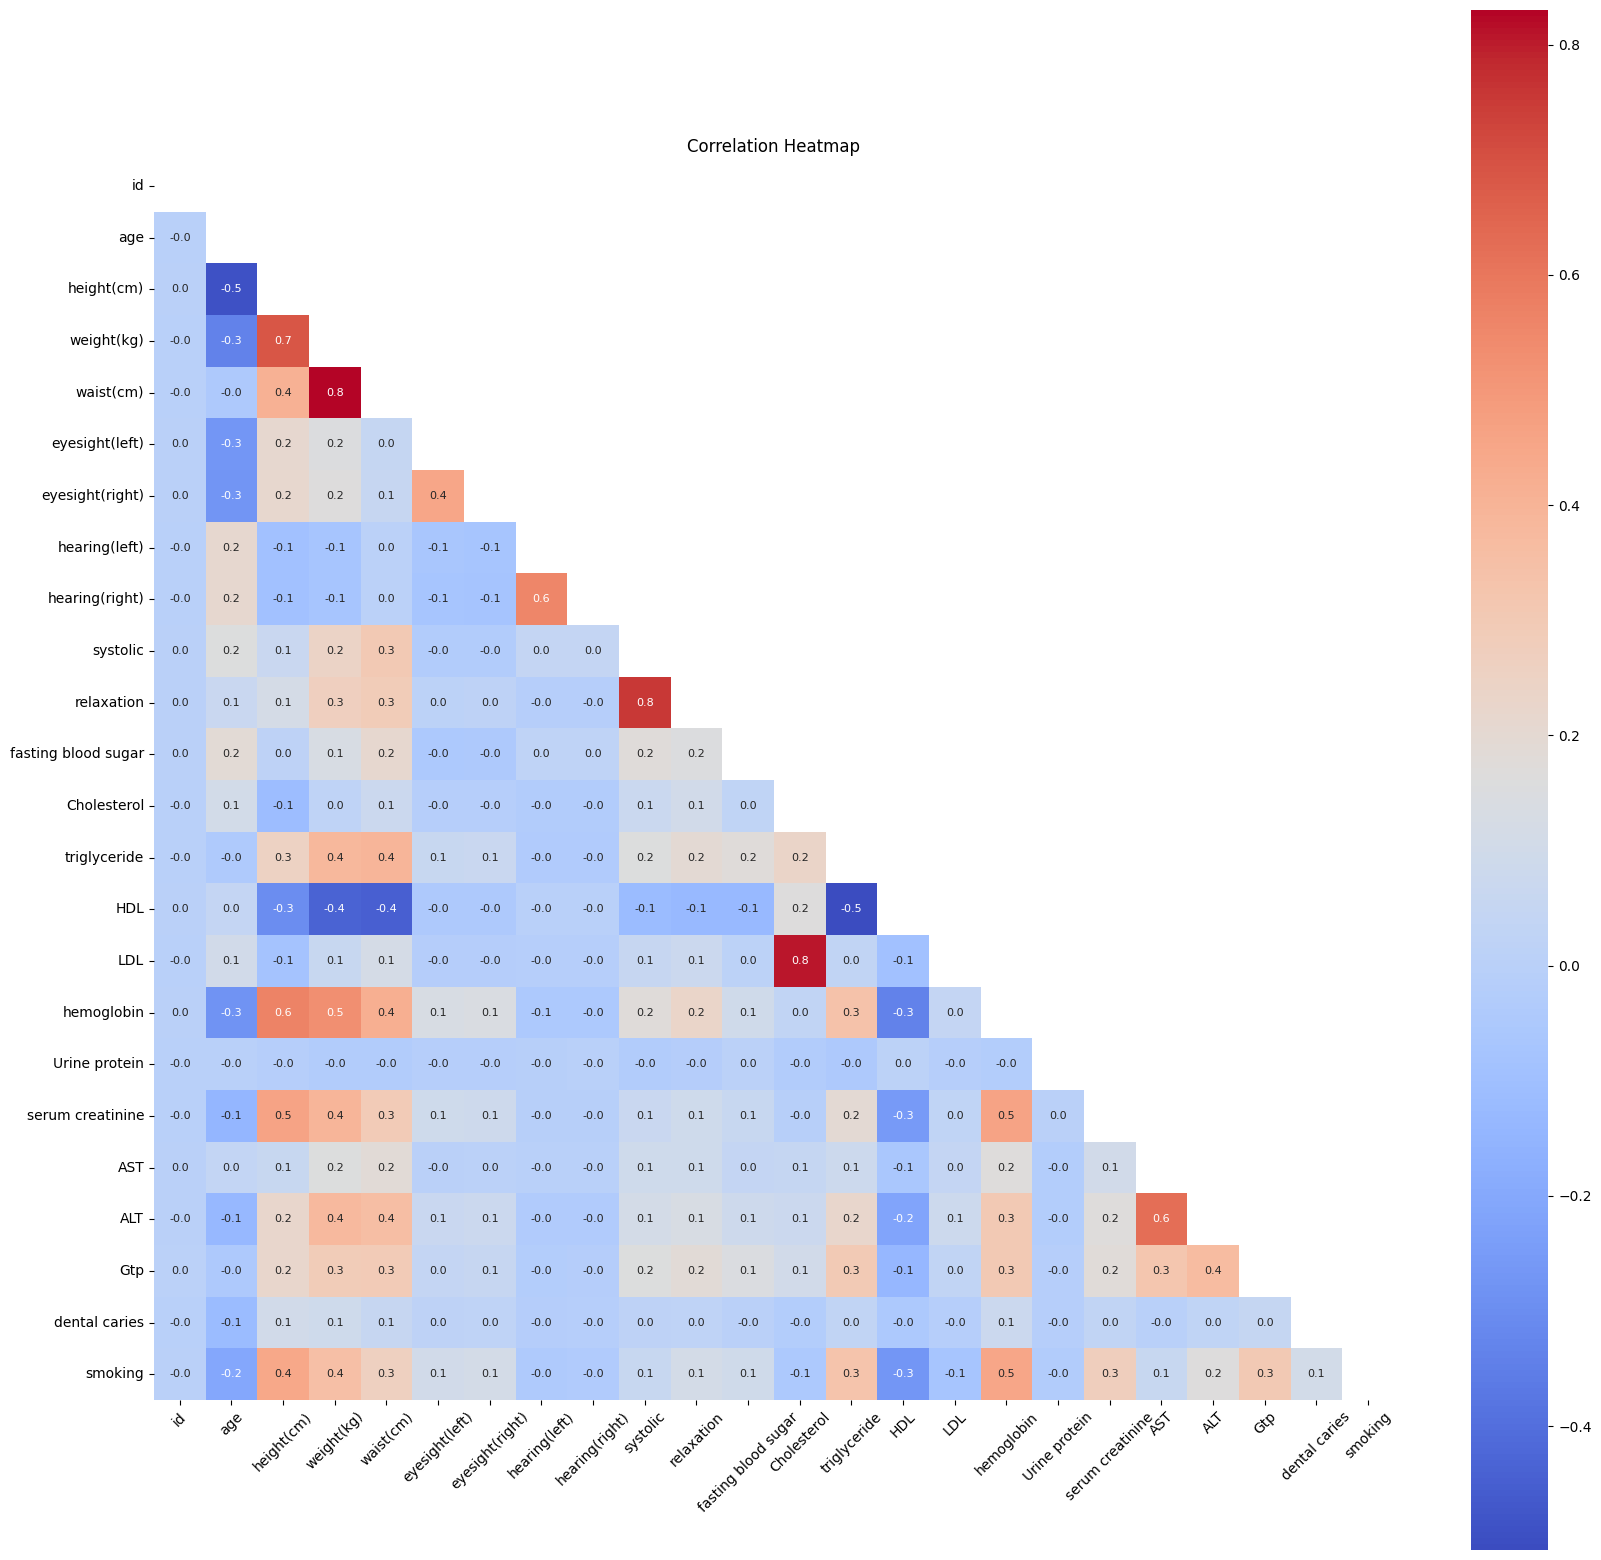

In [ ]:
#heatmap for correlation
import numpy as np
plt.figure(figsize=(20, 20))  # Increase figure size
corr = train.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))  # Mask for the upper triangle
sns.heatmap(corr, annot=True, fmt=".1f", cmap='coolwarm', mask=mask, square=True, annot_kws={"size": 8})
plt.xticks(rotation=45)  # Rotate x labels
plt.yticks(rotation=0)   # Rotate y labels if needed
plt.title('Correlation Heatmap')
plt.show()



In [ ]:
plt.savefig('correlation_heatmap.png', bbox_inches='tight')

from google.colab import files
files.download('correlation_heatmap.png')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 640x480 with 0 Axes>

In [ ]:
from sklearn.preprocessing import StandardScaler

# Select only the numerical features for standardization.
numerical_features = train.select_dtypes(include=['int64', 'float64'])

# Initialize the scaler.
scaler = StandardScaler()

# Fit the scaler.
scaler.fit(numerical_features)

# Transform the data and replace in the DataFrame.
train[numerical_features.columns] = scaler.transform(numerical_features)

print(train)




              id       age  height(cm)  weight(kg)  waist(cm)  eyesight(left)  \
0      -1.732040  0.902985   -0.030268   -0.567581  -0.223489       -1.257856   
1      -1.732018  2.169636   -0.030268   -0.170319   0.669577       -1.009169   
2      -1.731996 -2.052535    0.536694    0.624205  -0.223489       -1.506543   
3      -1.731975 -0.785883    1.670617    2.213252   2.455708        1.229017   
4      -1.731953 -1.208100   -0.030268   -0.567581  -0.279305        1.229017   
...          ...       ...         ...         ...        ...             ...   
159251  1.731953 -0.363666   -1.164191   -1.759366  -1.563087        1.229017   
159252  1.731975  0.480768   -1.164191    0.624205  -0.111855       -0.014419   
159253  1.731996 -0.363666   -0.597229   -1.362104  -1.897986        1.229017   
159254  1.732018  0.480768   -0.030268    0.624205   1.004477        0.482955   
159255  1.732040 -0.363666   -2.298113   -1.759366  -0.737001       -0.014419   

        eyesight(right)  he

## 2. Class imbalance and a baseline random forest
Non-smokers outnumber smokers, so the baseline random forest uses balanced class weights.

Prepare the features (all columns except `id` and `smoking`) and the target.

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score

# Load the dataset
train = pd.read_csv('train.csv')

# Selecting features and target
X = train.drop([ 'smoking'], axis=1)
y = train['smoking']


Hold out 30% of the data for testing.

In [ ]:
# Splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)  # 30% for testing


Balanced class weights penalize errors on the smaller (smoker) class more heavily.

In [ ]:
# Create a RandomForest model with balanced class weights
model = RandomForestClassifier(class_weight='balanced', random_state=42)


Train the model.

In [ ]:
# Train the model
model.fit(X_train, y_train)


RandomForestClassifier(class_weight='balanced', random_state=42)

Evaluate on the held-out set.

In [ ]:
# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Accuracy Score:", accuracy_score(y_test, y_pred))


Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.76      0.79     26686
           1       0.72      0.79      0.75     21091

    accuracy                           0.77     47777
   macro avg       0.77      0.77      0.77     47777
weighted avg       0.78      0.77      0.77     47777

Accuracy Score: 0.7717311677166837


## 3. Hyperparameter tuning

Grid search with 3-fold cross-validation over the number of trees, maximum depth and minimum split size.

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Define the model with a random state for reproducibility
model = RandomForestClassifier(random_state=42)

# Define a more focused parameter grid to explore fewer combinations of hyperparameters
param_grid = {
    'n_estimators': [100, 150],  # Reduced the upper range to speed up the process
    'max_depth': [10, 20],       # Fewer options to evaluate
    'min_samples_split': [2, 5]  # Fewer options to speed up the evaluation
}

# Setup the grid search with cross-validation
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=3,                            # Keeping 3 folds to maintain a good balance of validation
    scoring='accuracy',              # Metric for evaluating the models
    verbose=2,                       # Detailed output to monitor progress
    n_jobs=-1                        # Using all processors to maximize speed
)

# Fit grid search to the data
best_model = grid_search.fit(X_train, y_train)

# Print the best parameters found during the grid search
print("Best parameters found: ", best_model.best_params_)


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters found:  {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 150}


## 4. Other models
Logistic regression and gradient boosting, fitted on a 1% sample to keep run time manageable.

In [ ]:
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Reduce the dataset drastically
data_sample = train.sample(frac=0.01, random_state=42)  # Using only 1% of the data
X_sample = data_sample.drop([ 'smoking'], axis=1)
y_sample = data_sample['smoking']

# Quick split for immediate testing
X_train, X_test, y_train, y_test = train_test_split(X_sample, y_sample, test_size=0.5, random_state=42)

# Using a very simple Logistic Regression for immediate results
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)
lr_accuracy = accuracy_score(y_test, lr_predictions)

# Simplify the Gradient Boosting Classifier
gbm_model = GradientBoostingClassifier(n_estimators=10, learning_rate=0.5, max_depth=1, random_state=42)
gbm_model.fit(X_train, y_train)
gbm_predictions = gbm_model.predict(X_test)
gbm_accuracy = accuracy_score(y_test, gbm_predictions)

# Output the results
print("Logistic Regression Accuracy: {:.2f}".format(lr_accuracy))
print("GBM Accuracy: {:.2f}".format(gbm_accuracy))


Logistic Regression Accuracy: 0.69
GBM Accuracy: 0.72


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Logistic regression: fixing the convergence warning
Three changes were tried:

1. More iterations (`max_iter=1000`).

In [ ]:
lr_model = LogisticRegression(random_state=42, max_iter=1000)


2. Standardize the features before fitting.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)
lr_predictions = lr_model.predict(X_test_scaled)
lr_accuracy = accuracy_score(y_test, lr_predictions)


3. A different solver (`saga`).

In [ ]:
lr_model = LogisticRegression(random_state=42, max_iter=1000, solver='saga')


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Initialize the logistic regression model
lr_model = LogisticRegression(random_state=42)

# X_train and X_test come from the split above
# Scale the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # Fit and transform scaler on training data
X_test_scaled = scaler.transform(X_test)        # Apply same transformation to test data

# Fit the logistic regression model
lr_model.fit(X_train_scaled, y_train)

# Predict probabilities and calculate ROC-AUC
lr_predictions = lr_model.predict(X_test_scaled)
lr_probabilities = lr_model.predict_proba(X_test_scaled)[:, 1]  # Probabilities for class 1
roc_auc = roc_auc_score(y_test, lr_probabilities)
print("ROC-AUC Score:", roc_auc)


ROC-AUC Score: 0.8168723759421317


In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Load and prepare training data
train = pd.read_csv('train.csv')
X_train = train.drop(['id', 'smoking'], axis=1)
y_train = train['smoking']

# Initialize and fit the scaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Initialize and fit the logistic regression model
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

# Load the test data
test = pd.read_csv('test.csv')
X_test = test.drop(['id'], axis=1)

# Scale the test features using the previously fitted scaler
X_test_scaled = scaler.transform(X_test)

# Generate probability predictions for the positive class
test_probabilities = model.predict_proba(X_test_scaled)[:, 1]

# Create and save the submission DataFrame
submission = pd.DataFrame({
    'id': test['id'],
    'smoking': test_probabilities
})
submission.to_csv('submission.csv', index=False)


## 5. Feature importance
Which measurements does the random forest rely on most?

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

# X_train and y_train come from the split above
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Get feature importance
feature_importance = pd.DataFrame(model.feature_importances_, index=X_train.columns, columns=['importance']).sort_values('importance', ascending=False)

# Display the feature importance
print(feature_importance)


                     importance
height(cm)             0.120441
hemoglobin             0.114839
Gtp                    0.100263
triglyceride           0.080265
LDL                    0.048728
HDL                    0.047046
Cholesterol            0.046870
weight(kg)             0.046756
ALT                    0.045998
waist(cm)              0.044791
fasting blood sugar    0.042899
serum creatinine       0.041802
systolic               0.040590
AST                    0.039718
relaxation             0.038302
age                    0.037543
eyesight(left)         0.024737
eyesight(right)        0.024686
dental caries          0.006821
Urine protein          0.003857
hearing(right)         0.001545
hearing(left)          0.001504


## 6. Visualizing the results

### ROC curve

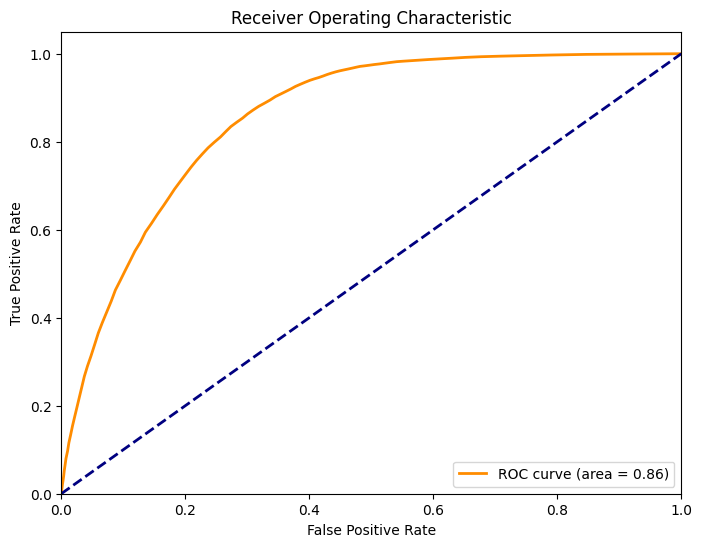

In [ ]:
from sklearn.metrics import roc_curve, auc

# Compute ROC curve and ROC area
fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
roc_auc = auc(fpr, tpr)

# Plotting
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()


### Feature importance plot

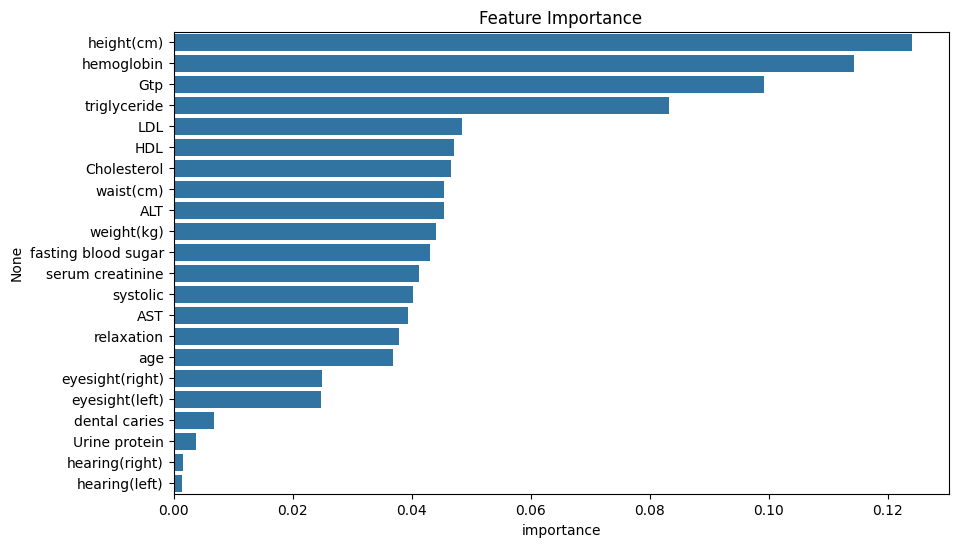

In [ ]:
feature_importances = pd.DataFrame(model.feature_importances_,
                                   index = X_train.columns,
                                   columns=['importance']).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importances['importance'], y=feature_importances.index)
plt.title('Feature Importance')
plt.show()


## 7. Model comparison
Random forest, logistic regression, XGBoost and LightGBM, compared by ROC AUC on a reduced sample.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

# X and y as defined above

# Reduce the data size for quicker execution
X_sample, _, y_sample, _ = train_test_split(X, y, train_size=0.1, stratify=y, random_state=42)

# Further split the sample data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_sample, y_sample, test_size=0.3, random_state=42)

# Initialize a smaller set of models with reduced complexity for faster training
models = {
    'RandomForest': RandomForestClassifier(n_estimators=10, random_state=42),  # fewer trees
    'LogisticRegression': LogisticRegression(solver='liblinear', random_state=42),  # faster solver
    'XGBClassifier': XGBClassifier(n_estimators=50, random_state=42),  # fewer trees
    'LGBMClassifier': LGBMClassifier(n_estimators=50, random_state=42),  # fewer trees
}

# Dictionary to store the best AUC scores
best_auc_scores = {}

# Evaluate each model without cross-validation for quicker execution
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict_proba(X_test)[:, 1]
    auc_score = roc_auc_score(y_test, predictions)
    best_auc_scores[name] = auc_score
    print(f'{name} AUC: {auc_score}')

# Identify the best model from the simplified run
best_model_name = max(best_auc_scores, key=best_auc_scores.get)
best_model = models[best_model_name]
print(f'Best Model: {best_model_name} with AUC: {best_auc_scores[best_model_name]}')

# Final training on a small sample and prediction
final_predictions = best_model.predict_proba(X_test)[:, 1]

# test_ids would come from the Kaggle test file
# test_ids = ...

# Create submission file
submission = pd.DataFrame({
    'id': test['id'],
    'smoking': test_probabilities
})

submission.to_csv('final_submission.csv', index=False)





RandomForest AUC: 0.8141605961681018
LogisticRegression AUC: 0.8269310956834122
XGBClassifier AUC: 0.841544662713121
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 4885, number of negative: 6262
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001150 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1685
[LightGBM] [Info] Number of data points in the train set: 11147, number of used features: 22
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.438235 -> initscore=-0.248330
[LightGBM] [Info] Start training from score -0.248330
LGBMClassifier AUC: 0.8495406141301248
Best Model: LGBMClassifier with AUC: 0.8495406141301248


## 8. Height as a categorical variable
Height ranked highest in feature importance. Does grouping it into five bands change performance?

In [ ]:
# import required libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


#load the training data
import pandas as pd
df = pd.read_csv('train.csv')
df.head()
# preprocess data
# Define bins for height categorization
bins = [0, 150, 165, 180, 195, 250]  # height bands in cm
labels = ['Very Short', 'Short', 'Medium', 'Tall', 'Very Tall']
df['height_cat'] = pd.cut(df['height(cm)'], bins=bins, labels=labels, include_lowest=True)

# Prepare features and target
X = df.drop(['smoking', 'height(cm)'], axis=1)  # Remove original height and smoking column
y = df['smoking']

define preprocessing and modeling pipeline
# Preprocessing for categorical data: applying one-hot encoding
categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessors with a column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, ['height_cat'])  # Apply one-hot to height categories
    ])

# Append classifier to preprocessing pipeline.
# Full prediction pipeline.
clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

split data and train model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

clf.fit(X_train, y_train)

evaluate model
y_pred = clf.predict(X_test)
print("Model Accuracy:", accuracy_score(y_test, y_pred))
print("ROC AUC Score:", roc_auc_score(y_test, clf.predict_proba(X_test)[:, 1]))
